In [ ]:
!pip -q install datasets scikit-learn pandas matplotlib seaborn joblib

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
dataset = load_dataset("dair-ai/emotion")
train_df = dataset["train"].to_pandas()
val_df = dataset["validation"].to_pandas()
test_df = dataset["test"].to_pandas()
print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))
print("\nSample data:")
display(train_df.head())

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Training samples: 16000
Validation samples: 2000
Testing samples: 2000

Sample data:


,text,label
0,i didnt feel humiliated,0
1,i can go from feeling so hopeless to so damned...,0
2,im grabbing a minute to post i feel greedy wrong,3
3,i am ever feeling nostalgic about the fireplac...,2
4,i am feeling grouchy,3


Emotion labels: ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

Missing values:
text     0
label    0
dtype: int64


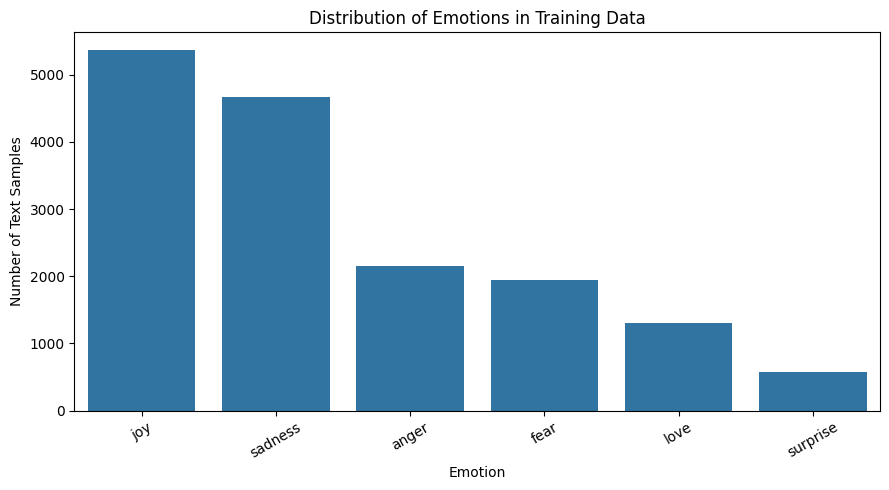

In [ ]:
label_names = dataset["train"].features["label"].names
print("Emotion labels:", label_names)
print("\nMissing values:")
print(train_df.isnull().sum())
train_df["emotion"] = train_df["label"].map(
    lambda x: label_names[x]
)
plt.figure(figsize=(9, 5))
sns.countplot(
    data=train_df,
    x="emotion",
    order=train_df["emotion"].value_counts().index
)
plt.title("Distribution of Emotions in Training Data")
plt.xlabel("Emotion")
plt.ylabel("Number of Text Samples")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
X_train_text = train_df["text"].fillna("").astype(str)
X_val_text = val_df["text"].fillna("").astype(str)
X_test_text = test_df["text"].fillna("").astype(str)
y_train = train_df["label"]
y_val = val_df["label"]
y_test = test_df["label"]
tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    sublinear_tf=True
)
X_train = tfidf.fit_transform(X_train_text)
X_val = tfidf.transform(X_val_text)
X_test = tfidf.transform(X_test_text)
print("Training feature shape:", X_train.shape)
print("Validation feature shape:", X_val.shape)
print("Testing feature shape:", X_test.shape)

Training feature shape: (16000, 20000)
Validation feature shape: (2000, 20000)
Testing feature shape: (2000, 20000)


In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),
    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=42
    )
}
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_val)

    results.append({
        "Model": name,
        "Validation Accuracy": accuracy_score(
            y_val, predictions
        ),
        "Validation Macro F1": f1_score(
            y_val, predictions, average="macro"
        )
    })
results_df = pd.DataFrame(results).sort_values(
    "Validation Macro F1", ascending=False
)
display(results_df)

,Model,Validation Accuracy,Validation Macro F1
1,Linear SVM,0.9075,0.881862
0,Logistic Regression,0.8790,0.851009


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score
)

best_name = results_df.iloc[0]["Model"]
best_model = models[best_name]

test_predictions = best_model.predict(X_test)

metrics = {
    "Model": best_name,
    "Test Accuracy": accuracy_score(y_test, test_predictions),
    "Macro Precision": precision_score(
        y_test, test_predictions, average="macro",
        zero_division=0
    ),
    "Macro Recall": recall_score(
        y_test, test_predictions, average="macro",
        zero_division=0
    ),
    "Macro F1": f1_score(
        y_test, test_predictions, average="macro",
        zero_division=0
    ),
    "Weighted F1": f1_score(
        y_test, test_predictions, average="weighted",
        zero_division=0
    )
}

print("Selected model:", best_name)
display(pd.DataFrame([metrics]).round(4))

print("\nDetailed Classification Report:")
print(classification_report(
    y_test,
    test_predictions,
    labels=list(range(len(label_names))),
    target_names=label_names,
    zero_division=0
))


Selected model: Linear SVM


,Model,Test Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,Linear SVM,0.88,0.8236,0.8377,0.8297,0.8809



Detailed Classification Report:
              precision    recall  f1-score   support

     sadness       0.92      0.91      0.92       581
         joy       0.92      0.90      0.91       695
        love       0.72      0.83      0.77       159
       anger       0.88      0.89      0.88       275
        fear       0.86      0.81      0.84       224
    surprise       0.64      0.68      0.66        66

    accuracy                           0.88      2000
   macro avg       0.82      0.84      0.83      2000
weighted avg       0.88      0.88      0.88      2000



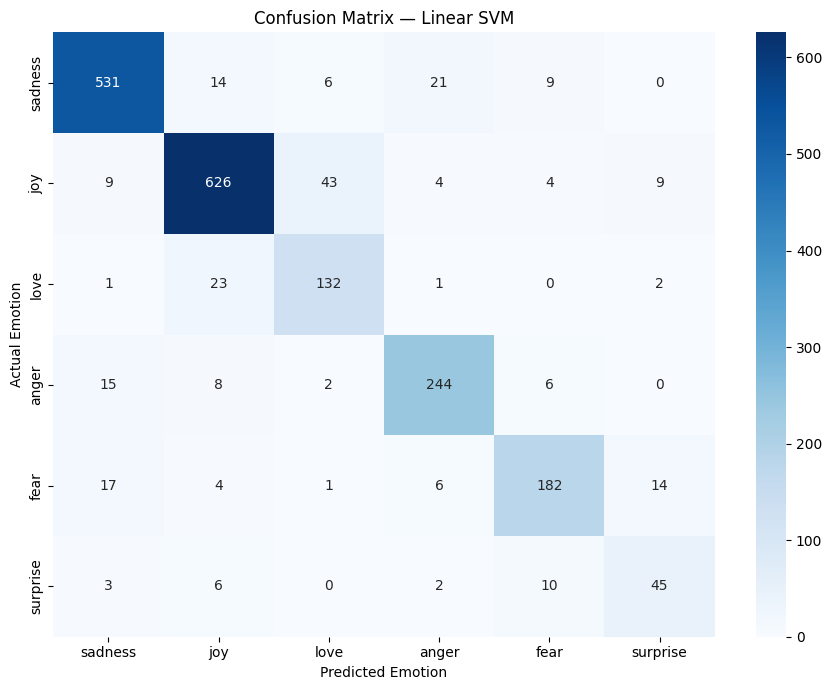

In [ ]:

cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=list(range(len(label_names)))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_names,
    yticklabels=label_names
)
plt.title(f"Confusion Matrix — {best_name}")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()


In [ ]:

def predict_emotion(text):
    if not isinstance(text, str) or not text.strip():
        raise ValueError("Please enter a non-empty sentence.")

    features = tfidf.transform([text])
    prediction = best_model.predict(features)[0]

    return label_names[int(prediction)]


test_sentences = [
    "I am so happy today!",
    "I feel very sad and lonely.",
    "I am furious about what happened.",
    "I am scared of what might happen.",
    "I was surprised by the unexpected gift.",
    "I love spending time with my family.",
    "The meeting is scheduled for tomorrow.",
    "",
    "I AM SO HAPPY!!!"
]

for sentence in test_sentences:
    try:
        print(f"Text: {sentence!r}")
        print(f"Predicted emotion: {predict_emotion(sentence)}\n")
    except ValueError as error:
        print(f"Input validation: {error}\n")


Text: 'I am so happy today!'
Predicted emotion: joy

Text: 'I feel very sad and lonely.'
Predicted emotion: sadness

Text: 'I am furious about what happened.'
Predicted emotion: anger

Text: 'I am scared of what might happen.'
Predicted emotion: fear

Text: 'I was surprised by the unexpected gift.'
Predicted emotion: surprise

Text: 'I love spending time with my family.'
Predicted emotion: joy

Text: 'The meeting is scheduled for tomorrow.'
Predicted emotion: joy

Text: ''
Input validation: Please enter a non-empty sentence.

Text: 'I AM SO HAPPY!!!'
Predicted emotion: joy



In [ ]:

def run_unit_tests():
    # Normal sentence
    result = predict_emotion("I feel wonderful today")
    assert result in label_names

    # Another normal sentence
    result = predict_emotion("I am worried about my exam")
    assert result in label_names

    # Empty input should be rejected
    try:
        predict_emotion("")
        raise AssertionError("Empty input was not rejected")
    except ValueError:
        pass

    # Whitespace-only input should be rejected
    try:
        predict_emotion("   ")
        raise AssertionError("Whitespace input was not rejected")
    except ValueError:
        pass

    # Invalid input type should be rejected
    try:
        predict_emotion(None)
        raise AssertionError("Invalid input type was not rejected")
    except ValueError:
        pass

    print("All 5 unit tests passed!")


run_unit_tests()


All 5 unit tests passed!


In [ ]:

import json
import joblib
from pathlib import Path

Path("results").mkdir(exist_ok=True)
Path("models").mkdir(exist_ok=True)

# Save model and vectorizer
joblib.dump(best_model, "models/emotion_model.joblib")
joblib.dump(tfidf, "models/tfidf_vectorizer.joblib")

# Save metrics and model comparison
with open("results/test_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

results_df.to_csv(
    "results/model_comparison.csv", index=False
)

pd.DataFrame({
    "text": X_test_text,
    "actual_emotion": [label_names[int(i)] for i in y_test],
    "predicted_emotion": [
        label_names[int(i)] for i in test_predictions
    ]
}).to_csv("results/test_predictions.csv", index=False)

print("Models and evaluation results saved successfully.")


Models and evaluation results saved successfully.


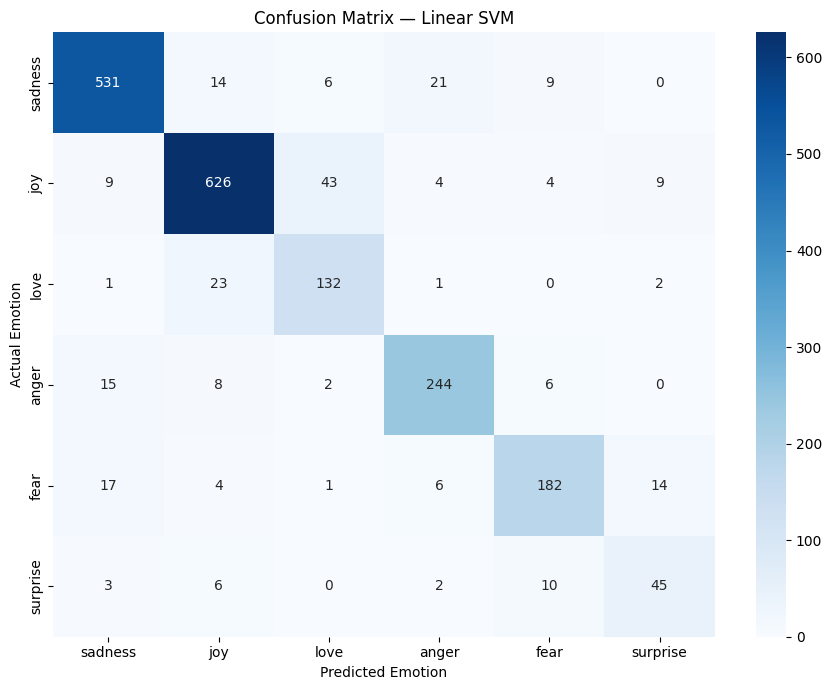

Evaluation report and confusion matrix saved.


In [ ]:

from sklearn.metrics import classification_report
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Path("results").mkdir(exist_ok=True)

# Save detailed class-wise evaluation
report = classification_report(
    y_test,
    test_predictions,
    labels=list(range(len(label_names))),
    target_names=label_names,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    "results/classification_report.csv"
)

# Save confusion matrix image
cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=list(range(len(label_names)))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=label_names,
    yticklabels=label_names
)
plt.title(f"Confusion Matrix — {best_name}")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.tight_layout()
plt.savefig("results/confusion_matrix.png", dpi=300)
plt.show()

print("Evaluation report and confusion matrix saved.")
